2025-10-20
This code takes the _MZdata datafiles (made from Jordan's sorting program and my Jupyter notebook) and makes a new file with the simple average activity score, DNA and AA sequences, and sequence properties.

1. Reads histograms and BC statistics are plotted
2. Simple average of activity is calculated, outliers (>2.6*standard deviation) are excluded and average is recalculated
3. Sequence features are for each AA sequence (Charge, HydrophobicityKD, HydrophobicityWW, Aromatics, WYFL, all #AAs) are added to delta from a seqfeats design file
4. Predictions for each AA sequence are added to delta from a prediction design file
5. Standardized activity is calculated from the controls library
6. Synthetic ADs: columns from old predictions and predictor combos are added; columns renamed
7. delta is saved to .csv at a filepath.

In [2]:
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit

%load_ext autoreload
%autoreload 2

import sys
sys.path.append(r"C:\Users\music\Desktop\CompLab\Global_Scripts")
from Helpful import *

In [3]:
# Edit these variables!

name = 'SynAD_mCherry_sort1'
name_color = "#f06593"

filetoprocess = r"..\..\data\labtools-processed\SynAD_1_mCherry_allinfo.csv"
filetosave = rf"..\..\data\{name}_processed.csv"

excludedsaving = True
excludedtosave = rf"..\..\data\excluded\{name}_EXCLUDED.csv"

figsaving = True
if figsaving == True:
    readsfigpath = rf'..\..\output\ProcessingFigs\{name}_Reads_Distributions.png'
    standardizingfigpath = rf'..\..\output\ProcessingFigs\{name}_MachineGaussian.png'
    activityfigpath = rf'..\..\output\ProcessingFigs\{name}_StdActivity_Distribution.png'
    gcn4corrpath = rf'..\..\output\ProcessingFigs\{name}_StdActivity_corr_Gcn4.png'
    stddevpath = rf'..\..\output\ProcessingFigs\{name}_StdActivity_corr_StdDev.png'

control_lib = False
if control_lib:
    control_color = '#9ce799'
    gcn4sort=pd.read_csv(r"..\..\..\Global_Data\Gcn4OrthologData_MZorganized_20251021.csv")
    gcn4sort = gcn4sort[['AAseq', 'Ratio_Activity', 'Ratio_StdDev', 'GFP_Activity', 'GFP_StdDev', 'mCherry_Activity', 'mCherry_StdDev']]
    sort_type = 'Ratio'

# DesignFile-based
seqfeats = pd.read_csv(r'..\..\..\DesignFiles\SeqFeat\SynADs_Ctrls_seqfeat.csv')

In [4]:
sort = pd.read_csv(filetoprocess,index_col=0)
sort

,DNAseq,AAseq,BC,Reads,0,1,2,3,Activity,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,AAATCTGATACTACTATGGAAGAAGATGAAGATGGTGATGTTTCTT...,KSDTTMEEDEDGDVSLSGGLESNFLDNLQCILDEDLVSAV,TTGATTACCTATGA,6178.0,2708.0,1879.0,1233.0,358.0,154.350678,1.0,6,10690.0
1,ATTGATTTGTCTAGATTGAATGGTTATGATCAATTGATTTTGGAAT...,IDLSRLNGYDQLILELEESLGDDQFMFINGVSSTVLGQWR,ATCTATCTAGCAGA,3562.0,2039.0,757.0,366.0,400.0,140.815736,1.0,5,7236.0
2,AAATCTAAATGTGAAAATATTGATCATTTGTTTTCTACTAGAGCTG...,KSKCENIDHLFSTRAEANETDEDSVPELLQHMFLEAFIDW,AGAAACCCCCGAAC,2944.0,1606.0,769.0,427.0,142.0,129.583752,1.0,2,4887.0
3,CCAGAAGAAGAAACTAAAGCTGCTGAACCAAATTATGGTTCTGTTG...,PEEETKAAEPNYGSVAISLPLERTISSQSMERSGSSSSGS,CAGCACAGTGTGTA,1621.0,133.0,179.0,31.0,1278.0,427.201933,1.0,4,4115.0
4,ATTTCTCCATTTTCTGATATGTTGATTGATGATCAACCATGGTCTT...,ISPFSDMLIDDQPWSFLMENDLFSAYMNLDKSNKVLFDVD,CCCTGTACCTAAAA,1421.0,540.0,388.0,273.0,220.0,192.296193,1.0,2,5246.0
...,...,...,...,...,...,...,...,...,...,...,...,...
45200,TTTAATTTTCCACATTTGTTGACTACTTCTTTGTCTGATGATTTTA...,FNFPHLLTTSLSDDFKGFFNDDDENIFPFFSALDDLLRES,TGCTATTAAAGGAG,51.0,0.0,0.0,0.0,51.0,517.000000,1.0,2,4621.0
45201,GGTGTTCCAGAATTGGCTTCTTTGGCTGGTTTGAATCCAATTCCAG...,GVPELASLAGLNPIPELLNGGGGDDNMDEFLDFSATRRGT,ACTTGACTTATTAT,48.0,0.0,0.0,0.0,48.0,517.000000,1.0,4,3084.0
45202,GATTCTATTCCATTGGATTCTAAACATTCTCAAGCTCCAAATGTTG...,DSIPLDSKHSQAPNVEEGIDHSLEEDLLYMYLDMDDKVPT,TATGAAATAAGGAT,65.0,0.0,0.0,0.0,65.0,517.000000,1.0,4,15941.0
45203,GATTCTCAAGAAATTGATGATATTAATGATTATTCTTTGACTTCTT...,DSQEIDDINDYSLTSLWGLRPDLLSTFFDSFFPTDGRNEK,AAAGAATACTATTA,46.0,0.0,0.0,0.0,46.0,517.000000,1.0,2,203.0


### 1: Reads Figures

C:\Users\music\AppData\Local\Temp\ipykernel_4260\288320538.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sortsub.drop_duplicates(inplace=True)


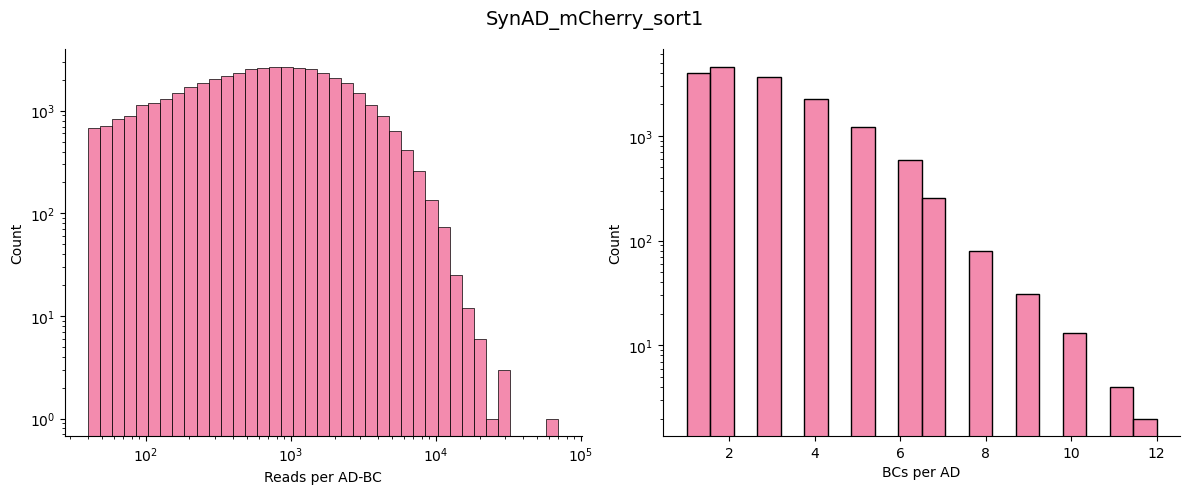

In [5]:
if control_lib:
    merge = pd.merge(sort, seqfeats[['AAseq','Ctrl']], on='AAseq', how='left')
    sort_ctrl = merge[merge['Ctrl']==1]
    sort_synad = merge[merge['Ctrl']==0]
# Create figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Reads (log bins)
minp = sort['Reads'].min()
maxp = sort['Reads'].max()
log_bins = np.logspace(np.log10(minp), np.log10(maxp), 40)

if control_lib:
    sns.histplot(sort_synad['Reads'], bins=log_bins, edgecolor='black', linewidth=0.5, ax=axes[0], color=name_color, alpha=0.5, label=f'{name}')
    sns.histplot(sort_ctrl['Reads'], bins=log_bins, edgecolor='black', linewidth=0.5, ax=axes[0], color=control_color, alpha=0.5, label='Control Library')
else:
    sns.histplot(sort['Reads'], bins=log_bins, edgecolor='black', linewidth=0.5, ax=axes[0], color=name_color)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('Reads per AD-BC')
axes[0].set_ylabel('Count')
sns.despine(ax=axes[0])

# Plot 2: BCs per AD
sortsub = sort[['AAseq', 'ADs_per_BC', "BCs_per_AD"]]
sortsub.drop_duplicates(inplace=True)
if control_lib:
    sortsub = merge[['AAseq', 'ADs_per_BC', "BCs_per_AD", 'Ctrl']]
    sortsub.drop_duplicates(inplace=True)
    sortsub_ctrl = sortsub[sortsub['Ctrl'] == 1]
    sortsub_synad = sortsub[sortsub['Ctrl'] == 0]
    sns.histplot(sortsub_synad['BCs_per_AD'], bins=20, ax=axes[1], color=name_color, alpha=0.5, label=f'{name}')
    sns.histplot(sortsub_ctrl['BCs_per_AD'], bins=20, ax=axes[1], color=control_color, alpha=0.5, label='Control Library')
else:
    sns.histplot(sortsub['BCs_per_AD'], bins=20, ax=axes[1], color=name_color)
axes[1].set_yscale('log')
axes[1].set_xlabel('BCs per AD')
axes[1].set_ylabel('Count')
sns.despine(ax=axes[1])

if control_lib:
    plt.legend()
plt.suptitle(name, fontsize=14)
plt.tight_layout()
plt.show()

if figsaving:
    fig.savefig(readsfigpath, dpi=300)

### 2: Calculating Average Activity per AAseq

In [6]:
help(simple_average_minus_outliers)

Help on function simple_average_minus_outliers in module Helpful:

simple_average_minus_outliers(df, aa_col: str = 'AAseq', activity_col: str = 'Activity', min_reps_for_std: int = 2, ddof: int = 1, thresh: float = 2.6)
    Calculate simple averages per-group, remove outliers, and recompute.

    Minimal, explicit behavior:
    - Groups by `aa_col` and collects replicate values from `activity_col`.
    - Raises ValueError if any replicate value cannot be converted to float.
    - Uses `remove_outliers` with the provided `thresh` to decide exclusions.

    Returns (included_df, excluded_df) where included_df has one row per group and
    excluded_df has one row per original excluded replicate.



In [7]:
filtered_df, excluded_df = simple_average_minus_outliers(sort, min_reps_for_std=2, ddof=1, thresh=2.6)
filtered_df

,AAseq,Activity,StdDev,NumReps,OriginalIndices,ReplicateActivities
0,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE,468.881757,NaN,1,[43015],[468.88175669465954]
1,AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,312.143504,NaN,1,[26959],[312.14350391747814]
2,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,240.421461,34.900357,4,"[2546, 4712, 7737, 24829]","[200.8547321832412, 230.19372143496915, 284.60..."
3,AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,252.884922,50.010381,4,"[10189, 16387, 19509, 29528]","[284.69152848486743, 252.51073740126745, 291.9..."
4,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,440.446675,NaN,1,[35670],[440.44667521968137]
...,...,...,...,...,...,...
16559,YYSDDIMLDLGVDLSNFQFDFRYFGLDSPLSPPWNEDDDS,161.573960,55.704165,3,"[1515, 2671, 21749]","[151.5415909737271, 111.56771615693737, 221.61..."
16560,YYSEQSCYLDLDLDLDITFLDFSQFLEQLLQSKNDPLVSE,159.374865,NaN,1,[20468],[159.37486466987525]
16561,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS,109.030773,NaN,1,[779],[109.03077294309456]
16562,YYSEQSCYLNFPPLDMFPALPSDLSGWVESMLSELNNPAS,250.454172,47.344796,2,"[10676, 22862]","[283.9319985567705, 216.97634592887587]"


In [8]:
excluded_df

,AAseq,OriginalIndex,FilteredOutActivity,ReplicateActivities,SimpleAverageBefore,SimpleAverageAfter,SimpleStdDevBefore,SimpleStdDevAfter
0,FLEDSGGTYESPNWSELSDFLFWNHYDGLLVSPCGLLNPF,45102,517.000000,"[158.41257427939436, 143.1738371321137, 91.249...",187.458760,154.504636,114.285330,35.204474
1,MECVEAFLGDFSVDDFSVDDFSVDDFSVDDFSVDDLLVDY,11894,226.560516,"[113.5392353649994, 138.59607149019405, 127.38...",131.335155,122.678304,36.389185,21.618695


ValueError: Axis limits cannot be NaN or Inf

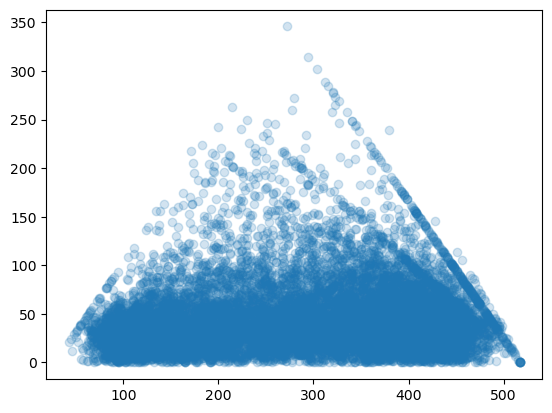

In [10]:
plt.scatter(filtered_df['Activity'], filtered_df['StdDev'], alpha=0.2)
plt.ylim(0, max(filtered_df['StdDev']))
plt.title(f'{name}\nActivity vs Standard Deviation')
plt.xlabel('Activity')
plt.ylabel('Standard Deviation')
if figsaving:
    plt.savefig(stddevpath, dpi=300)
plt.show()

In [12]:
filtered_df.columns

Index(['AAseq', 'Activity', 'StdDev', 'NumReps', 'OriginalIndices',
       'ReplicateActivities'],
      dtype='object')

### 8: Saving data

In [14]:
filtered_df.to_csv(filetosave)

In [15]:
if excludedsaving == True:
    excluded_df.to_csv(excludedtosave)

### 9: Extras